# Import Environment variables

In [2]:
%run /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables.ipynb

Found bucket: id=rw-migration-aou-rw-f7a4d148, bucketName=rw-migration-aou-rw-f7a4d148
-> Assigned migration variables (ID: rw-migration-aou-rw-f7a4d148)
Found bucket: id=temporary-workspace-bucket, bucketName=temporary-workspace-bucket-wb-perky-cabbage-8342
Found bucket: id=workspace-bucket, bucketName=workspace-bucket-wb-perky-cabbage-8342
✅ Successfully identified latest dataset: wb-silky-artichoke-2408.C2024Q3R9

Variables extracted:
GOOGLE_CLOUD_PROJECT: wb-perky-cabbage-8342
WORKSPACE_BUCKET: gs://workspace-bucket-wb-perky-cabbage-8342
WORKSPACE_TEMP_BUCKET: gs://temporary-workspace-bucket-wb-perky-cabbage-8342
WORKSPACE_CDR: wb-silky-artichoke-2408.C2024Q3R9
bucket_aou_tutorial: NOT FOUND
bucket_id_aou_tutorial: NOT FOUND
bucket_migrated: gs://rw-migration-aou-rw-f7a4d148
bucket_id_migrated: rw-migration-aou-rw-f7a4d148

✅ Saved to /home/jupyter/.bashrc
C2024Q3R9 BQ_DATASET
Multi-trait-GWAS-in-admixed-populations GIT_REPO
dataset_test2 BQ_DATASET
prep_C2024Q3R9 BQ_DATASET
rw-mig

In [3]:
%run /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables_p2.ipynb

WORKSPACE_CDR = wb-silky-artichoke-2408.C2024Q3R9
WORKSPACE_BUCKET = gs://workspace-bucket-wb-perky-cabbage-8342
GOOGLE_PROJECT = wb-perky-cabbage-8342
Done! 10 variables saved to: /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables_p2.R
Done! 10 variables saved to: /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables.sas


# Librairy

In [4]:
import os
import numpy as np
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt
from google.cloud import bigquery

# Data's import

In [5]:
# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

name_of_file_in_bucket = "df_54_RiskFactors_CurrentSmoking_AlcoholConsumption_Menopause_BMI_Height.tsv"

df = pd.read_csv(my_bucket +'/Data/'+ name_of_file_in_bucket, sep=',', low_memory=False)

In [6]:
df.columns

Index(['person_id', 'inclusion_date', 'first_breast_cancer_date', 'delay_days',
       'age_at_inclusion', 'has_bc', 'eur_rye', 'eas_rye', 'amr_rye',
       'afr_rye', 'sas_rye', 'mid_rye', 'dominant_origin', 'ancestry_80',
       'biopsy_result', 'age_category', 'race_us_bcsc', 'race_us_bcsc_detail',
       'breast_cancer_family_history_first_degree', 'tobacco_survey_date',
       'tobacco_answer_concept_id', 'tobacco_answer_label', 'smoking_status',
       'date_releve', 'jours_semaine', 'verres_jour_conso',
       'lifetime_intake_of_alcohol', 'alcohol_intake_category',
       'date_reference', 'bmi_measurement_date', 'ref_weight_kg',
       'ref_height_cm', 'ref_bmi', 'ref_bmi_category', 'ref_height_category'],
      dtype='object')

# EDA

## Analysis of missing data

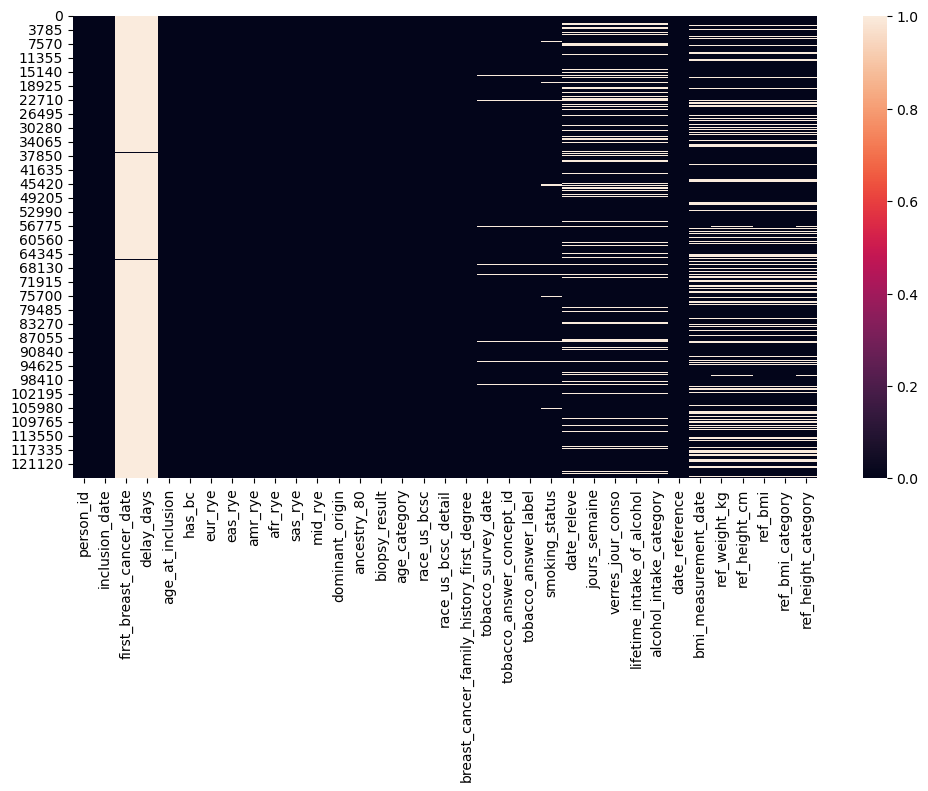

In [7]:
plt.figure(figsize=(12,6))
sns.heatmap(df.isna())
plt.show()

## Analysis of discrete quantitative data

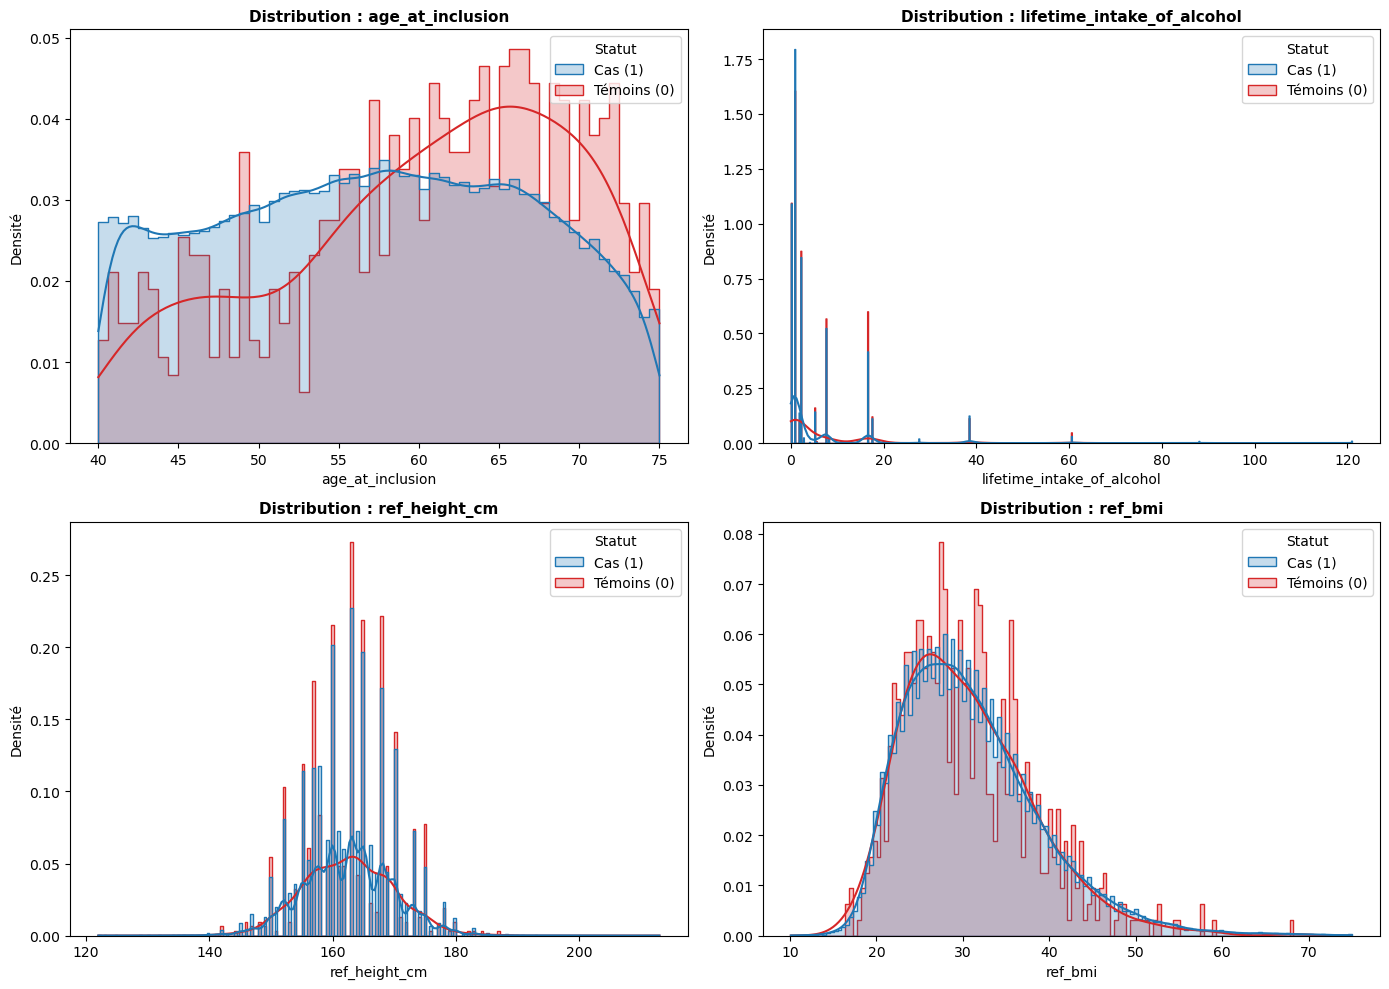

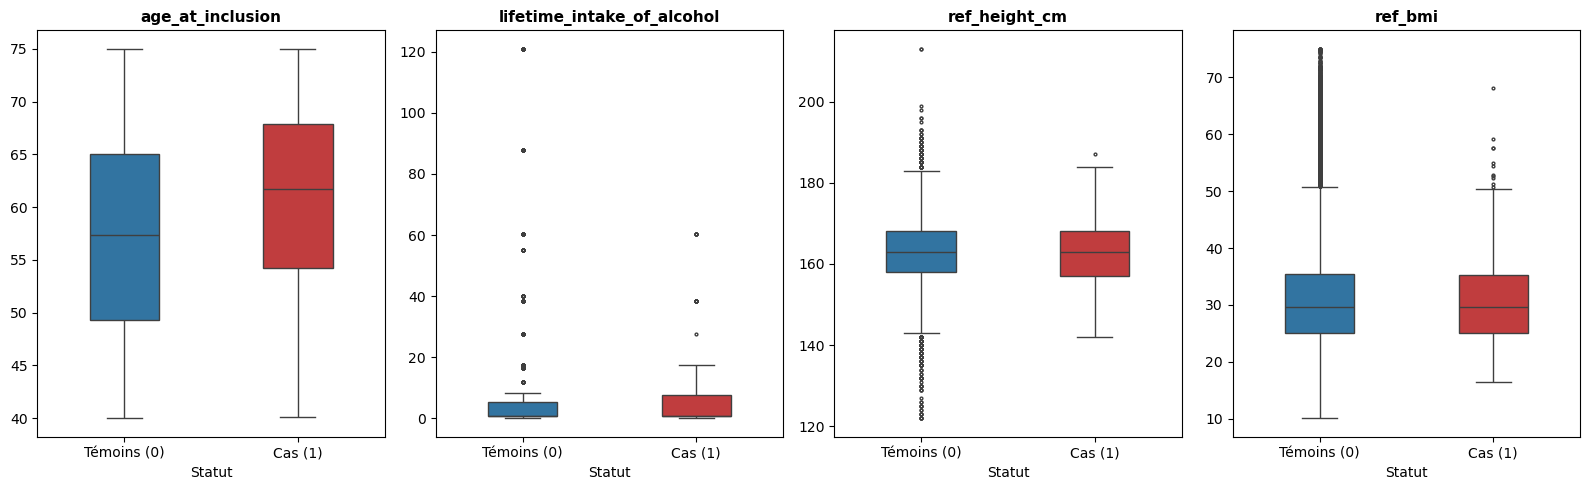

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = [
    "age_at_inclusion",
    "lifetime_intake_of_alcohol",
    "ref_height_cm",
    "ref_bmi",
]

# Palette avec clés sous forme de chaînes '0' et '1'
palette = {"0": "#1f77b4", "1": "#d62728"}

# Préparation propre de la colonne has_bc en type chaîne
df_temp = df.copy()
df_temp["has_bc"] = df_temp["has_bc"].astype(str)

# -------------------------------------------------------------------------
# 1. Visualisation des Distributions (Histogrammes + KDE)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    ax = sns.histplot(
        data=df_temp,
        x=col,
        hue="has_bc",
        kde=True,
        element="step",
        stat="density",
        common_norm=False,
        palette=palette,
        ax=axes[i],
    )
    axes[i].set_title(
        f"Distribution : {col}", fontsize=11, fontweight="bold"
    )
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Densité")

    # Mettre à jour la légende de Seaborn sans forcer les handles manuellement
    sns.move_legend(
        ax,
        "upper right",
        title="Statut",
        labels=["Cas (1)", "Témoins (0)"],
        frameon=True,
    )

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 2. Visualisation par Boxplots (Correction Seaborn 0.13+)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 5))

for i, col in enumerate(num_cols):
    sns.boxplot(
        data=df_temp,
        x="has_bc",
        y=col,
        hue="has_bc",  # Requis avec palette dans Seaborn 0.13+
        palette=palette,
        ax=axes[i],
        width=0.4,
        fliersize=2,
        legend=False,  # Supprime la légende redondante
    )
    axes[i].set_title(col, fontsize=11, fontweight="bold")
    axes[i].set_xlabel("Statut")
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["Témoins (0)", "Cas (1)"])
    axes[i].set_ylabel("")

plt.tight_layout()
plt.show()

## Analysis of continuous quantitative data

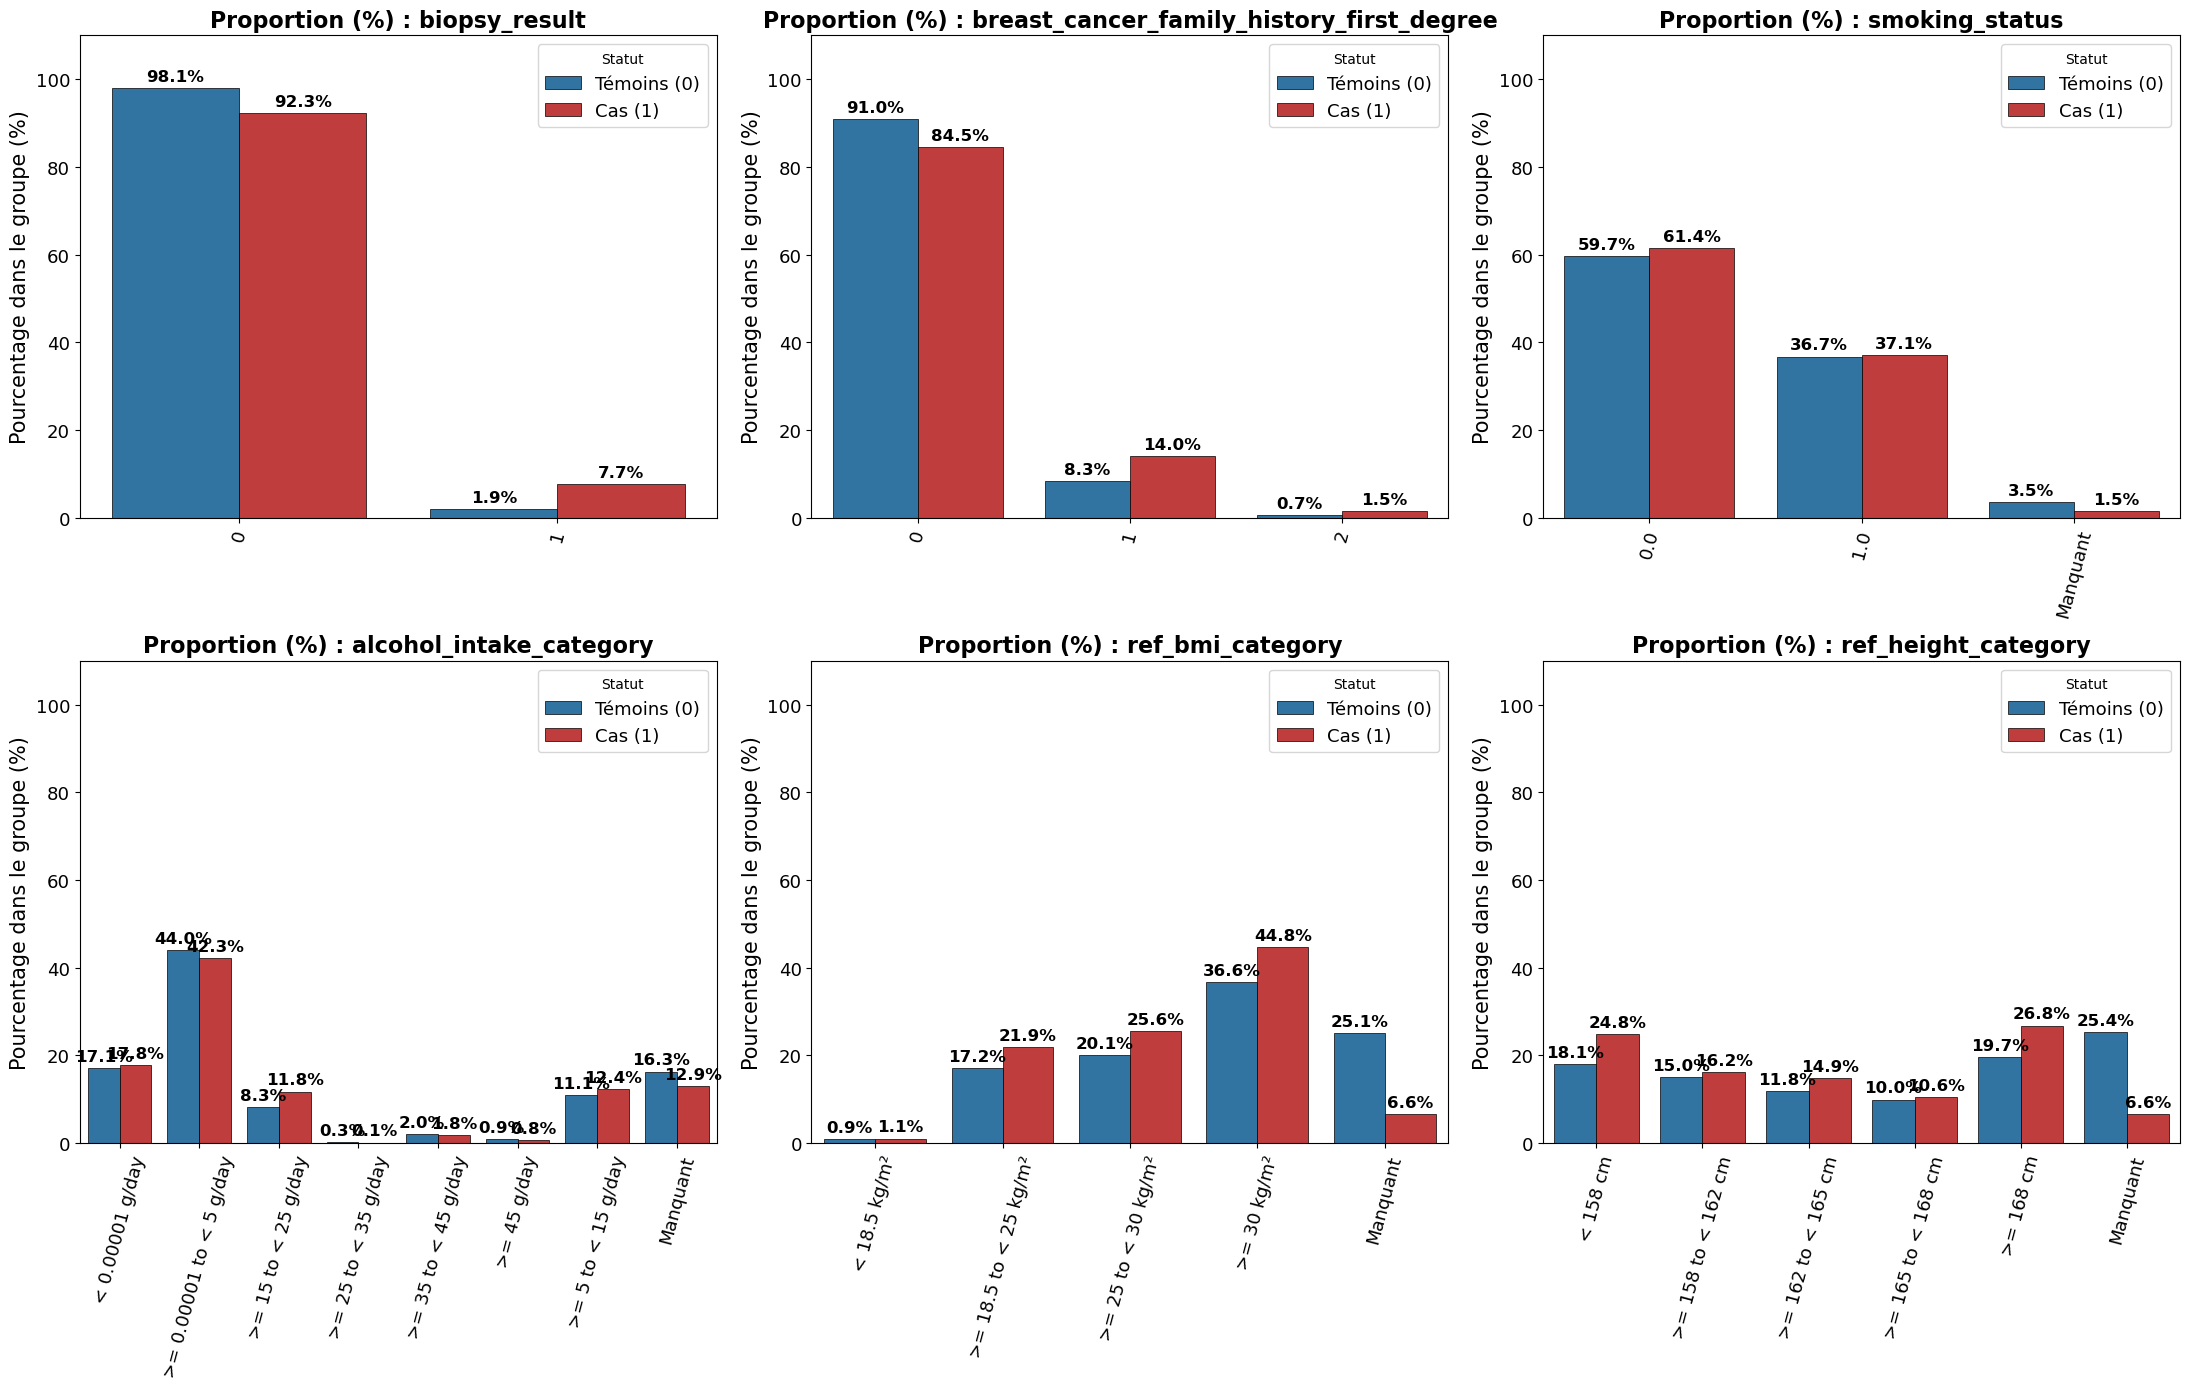

In [27]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Liste des variables catégorielles
cat_cols = [
    "biopsy_result",
    "breast_cancer_family_history_first_degree",
    "smoking_status",
    "alcohol_intake_category",
    "ref_bmi_category",
    "ref_height_category",
]

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(22, 14))
axes = axes.flatten()

palette = {0: "#1f77b4", 1: "#d62728"}  # Bleu = Témoins (0), Rouge = Cas (1)

for i, col in enumerate(cat_cols):
    # 1. Remplacement propre des NaN/None sans dupliquer tout le DataFrame
    series_col = (
        df[col]
        .fillna("Manquant")
        .astype(str)
        .replace({"nan": "Manquant", "None": "Manquant", "<NA>": "Manquant"})
    )

    # DataFrame temporaire léger pour le calcul
    temp_df = pd.DataFrame({"has_bc": df["has_bc"], col: series_col})

    # 2. Calcul du pourcentage normalisé au sein de chaque groupe has_bc (100% Cas / 100% Témoins)
    prop_df = (
        temp_df.groupby(["has_bc", col], observed=False)
        .size()
        .groupby(level=0)
        .transform(lambda x: 100 * x / x.sum())
        .reset_index(name="pourcentage")
    )

    # 3. Affichage graphique
    ax = sns.barplot(
        data=prop_df,
        x=col,
        y="pourcentage",
        hue="has_bc",
        ax=axes[i],
        palette=palette,
        edgecolor="black",
        linewidth=0.5,
    )

    # 4. Ajout des étiquettes de valeur au-dessus des barres
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f%%",  # Affichage au format "12.4%"
            padding=3,  # Espacement au-dessus de la barre
            fontsize=12,
            fontweight="bold",
        )

    # 5. Habillage du sous-graphique
    axes[i].set_title(
        f"Proportion (%) : {col}", fontsize=16, fontweight="bold"
    )
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Pourcentage dans le groupe (%)", fontsize=15)
    # Limite Y ajustée à 110% pour laisser la place aux étiquettes du haut
    axes[i].set_ylim(0, 110)
    axes[i].tick_params(axis="x", rotation=75, labelsize=13)
    axes[i].tick_params(axis="y", labelsize=13)

    # Gestion propre de la légende
    handles, _ = axes[i].get_legend_handles_labels()
    axes[i].legend(
        handles=handles, labels=["Témoins (0)", "Cas (1)"], title="Statut", fontsize=13
    )

plt.tight_layout()
plt.show()